In [1]:
from google.colab import files
uploaded = files.upload()

Saving deliveries.csv to deliveries.csv
Saving matches.csv to matches.csv


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

matches = pd.read_csv('matches.csv')
deliveries = pd.read_csv('deliveries.csv')

print("Matches Dataset:", matches.shape)
print("Deliveries Dataset:", deliveries.shape)

display(matches.head())

Matches Dataset: (1095, 20)
Deliveries Dataset: (260920, 17)


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


In [3]:
print("Missing Values:")
print(matches.isnull().sum())

matches = matches.dropna(subset=['winner'])

print("Cleaned Matches:", matches.shape)

Missing Values:
id                    0
season                0
city                 51
date                  0
match_type            0
player_of_match       5
venue                 0
team1                 0
team2                 0
toss_winner           0
toss_decision         0
winner                5
result                0
result_margin        19
target_runs           3
target_overs          3
super_over            0
method             1074
umpire1               0
umpire2               0
dtype: int64
Cleaned Matches: (1090, 20)


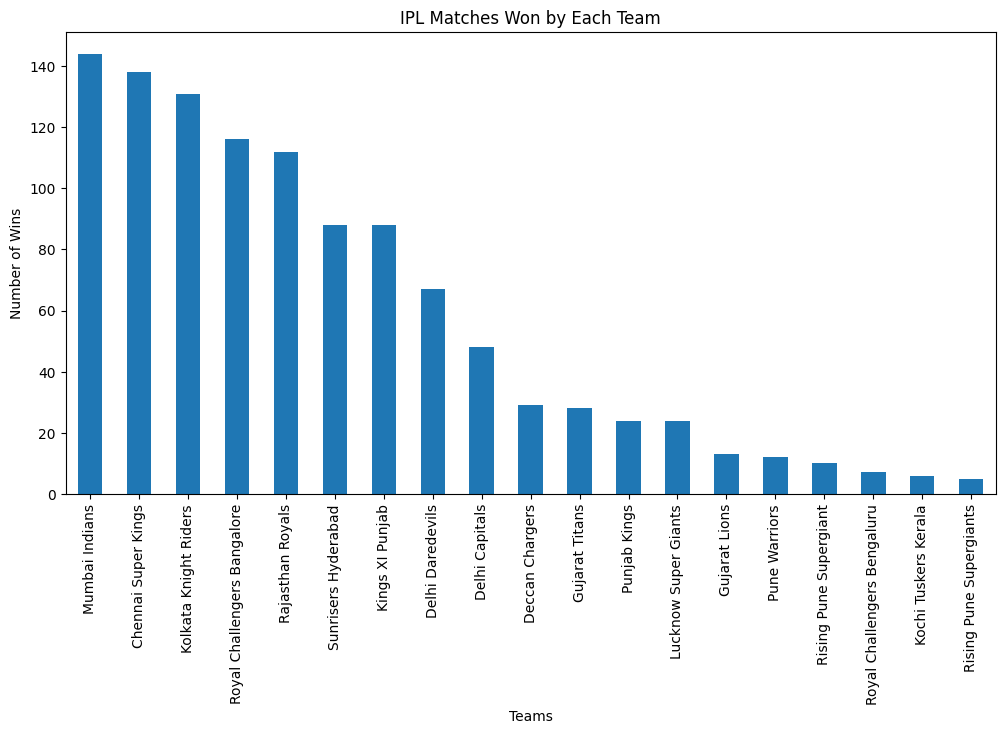

In [4]:
import matplotlib.pyplot as plt

wins = matches['winner'].value_counts()

plt.figure(figsize=(12, 6))
wins.plot(kind='bar')

plt.title('IPL Matches Won by Each Team')
plt.xlabel('Teams')
plt.ylabel('Number of Wins')
plt.xticks(rotation=90)
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

data = matches[['team1', 'team2', 'toss_winner',
                'toss_decision', 'venue', 'winner']].dropna()

for col in data.columns:
    data[col] = LabelEncoder().fit_transform(data[col])

X = data[['team1', 'team2', 'toss_winner',
          'toss_decision', 'venue']]
y = data['winner']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

print("Model Training Completed!")
print("Model Accuracy:", model.score(X_test, y_test))

Model Training Completed!
Model Accuracy: 0.47706422018348627


In [6]:
prediction = model.predict(X_test.iloc[[0]])

print("Predicted Winner Code:", prediction[0])
print("Actual Winner Code:", y_test.iloc[0])

Predicted Winner Code: 18
Actual Winner Code: 0


In [7]:
from sklearn.preprocessing import LabelEncoder

winner_encoder = LabelEncoder()
winner_encoder.fit(matches['winner'].dropna())

predicted_team = winner_encoder.inverse_transform(prediction)[0]
actual_team = winner_encoder.inverse_transform(
    [y_test.iloc[0]]
)[0]

print("Predicted Winner:", predicted_team)
print("Actual Winner:", actual_team)

Predicted Winner: Sunrisers Hyderabad
Actual Winner: Chennai Super Kings
